In [1]:
!apt-get install graphviz
!pip install graphviz

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
graphviz is already the newest version (2.42.2-9ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


In [2]:
ifrom graphviz import Digraph

# Create diagram
pipeline = Digraph(format="png")
pipeline.attr(rankdir="LR", size="8,5")

# Node styling
pipeline.attr("node", shape="box", style="rounded,filled", fillcolor="#E8F0FE", fontname="Helvetica")

# Nodes
pipeline.node("A", "Community Entry\n(Stigma-Free)\nCHWs • Chiefs • Trusted Groups")
pipeline.node("B", "Care-Without-Cost Buffer\nTransport • Food • Time Protection")
pipeline.node("C", "Parallel Processing\nReferral • Diagnostics Booking • CHW Assignment")
pipeline.node("D", "Single-Trip Clinic Visit\nTesting + Evaluation Same Day")
pipeline.node("E", "Treatment & Accompaniment\nAdherence • Nutrition • Side Effects")
pipeline.node("F", "Missed Visit?\nSupportive Re-Engagement\n(No Exclusion)")
pipeline.node("G", "Monitoring Data\n5 • 10 • 15 Year Outcomes")

# Edges
pipeline.edge("A", "B")
pipeline.edge("B", "C")
pipeline.edge("C", "D")
pipeline.edge("D", "E")
pipeline.edge("E", "F")
pipeline.edge("F", "E", label="Return to Care")
pipeline.edge("E", "G")

# Display
pipeline


SyntaxError: invalid syntax (2293905479.py, line 1)

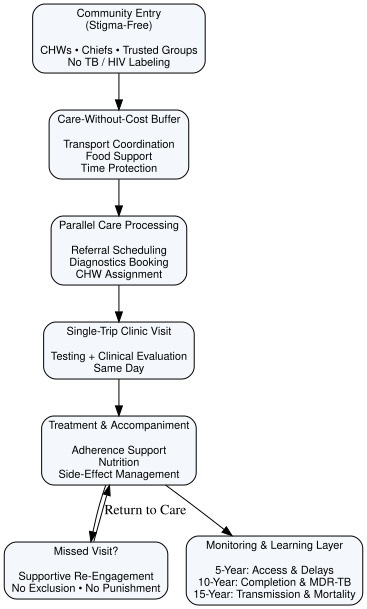

In [ ]:
from graphviz import Digraph

# Create vertical pipeline
pipeline = Digraph(format="png")
pipeline.attr(rankdir="TB", size="6,10")

# Global node style
pipeline.attr(
    "node",
    shape="box",
    style="rounded,filled",
    fillcolor="#F4F7FB",
    fontname="Helvetica",
    fontsize="11"
)

# Nodes (top to bottom)
pipeline.node(
    "A",
    "Community Entry\n(Stigma-Free)\n\nCHWs • Chiefs • Trusted Groups\nNo TB / HIV Labeling"
)

pipeline.node(
    "B",
    "Care-Without-Cost Buffer\n\nTransport Coordination\nFood Support\nTime Protection"
)

pipeline.node(
    "C",
    "Parallel Care Processing\n\nReferral Scheduling\nDiagnostics Booking\nCHW Assignment"
)

pipeline.node(
    "D",
    "Single-Trip Clinic Visit\n\nTesting + Clinical Evaluation\nSame Day"
)

pipeline.node(
    "E",
    "Treatment & Accompaniment\n\nAdherence Support\nNutrition\nSide-Effect Management"
)

pipeline.node(
    "F",
    "Missed Visit?\n\nSupportive Re-Engagement\nNo Exclusion • No Punishment"
)

pipeline.node(
    "G",
    "Monitoring & Learning Layer\n\n5-Year: Access & Delays\n10-Year: Completion & MDR-TB\n15-Year: Transmission & Mortality"
)

# Edges
pipeline.edge("A", "B")
pipeline.edge("B", "C")
pipeline.edge("C", "D")
pipeline.edge("D", "E")
pipeline.edge("E", "F")
pipeline.edge("F", "E", label="Return to Care")
pipeline.edge("E", "G")

pipeline


In [ ]:
!apt-get install graphviz
!pip install graphviz


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
graphviz is already the newest version (2.42.2-6ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
N = 5000

# Barrier index represents poverty, geography, stigma, time cost
barrier = np.clip(rng.beta(2, 2, size=N), 0, 1)

# BASELINE
encounters_baseline = rng.integers(2, 22, size=N)  # 2 to 21 encounters
days_between = np.clip(rng.lognormal(mean=2.0, sigma=0.6, size=N), 2, 45)
time_to_dx_baseline = np.clip(encounters_baseline * days_between + rng.normal(0, 7, size=N), 5, 365)

miss_prob_baseline = np.clip(0.15 + 0.35 * barrier, 0, 0.85)
missed_baseline = rng.random(size=N) < miss_prob_baseline

drop_prob_baseline = np.clip(0.18 + 0.25 * barrier + 0.20 * missed_baseline.astype(float), 0, 0.95)
dropped_baseline = rng.random(size=N) < drop_prob_baseline

infectious_days_baseline = np.where(dropped_baseline, np.clip(time_to_dx_baseline + 60, 30, 425), time_to_dx_baseline)

# PIPELINE
encounters_pipeline = np.where(rng.random(N) < 0.75, 1, 2)
days_between_pipeline = np.clip(rng.lognormal(mean=1.2, sigma=0.5, size=N), 1, 21)
time_to_dx_pipeline = np.clip(encounters_pipeline * days_between_pipeline + rng.normal(0, 4, size=N), 2, 120)

miss_prob_pipeline = np.clip(0.08 + 0.12 * barrier, 0, 0.50)
missed_pipeline = rng.random(size=N) < miss_prob_pipeline

drop_prob_pipeline = np.clip(0.10 + 0.15 * barrier + 0.10 * missed_pipeline.astype(float), 0, 0.70)
dropped_pipeline = rng.random(size=N) < drop_prob_pipeline

infectious_days_pipeline = np.where(dropped_pipeline, np.clip(time_to_dx_pipeline + 30, 15, 250), time_to_dx_pipeline)

df = pd.DataFrame({
    "barrier_index": barrier,
    "encounters_baseline": encounters_baseline,
    "days_to_dx_baseline": time_to_dx_baseline,
    "missed_visit_baseline": missed_baseline,
    "dropout_baseline": dropped_baseline,
    "infectious_days_baseline": infectious_days_baseline,
    "encounters_pipeline": encounters_pipeline,
    "days_to_dx_pipeline": time_to_dx_pipeline,
    "missed_visit_pipeline": missed_pipeline,
    "dropout_pipeline": dropped_pipeline,
    "infectious_days_pipeline": infectious_days_pipeline
})

summary = pd.DataFrame({
    "Metric": [
        "Median encounters before test",
        "Median days to diagnosis",
        "Missed visit rate",
        "Dropout rate",
        "Median infectious days proxy"
    ],
    "Baseline": [
        float(np.median(df["encounters_baseline"])),
        float(np.median(df["days_to_dx_baseline"])),
        float(df["missed_visit_baseline"].mean()),
        float(df["dropout_baseline"].mean()),
        float(np.median(df["infectious_days_baseline"]))
    ],
    "Pipeline": [
        float(np.median(df["encounters_pipeline"])),
        float(np.median(df["days_to_dx_pipeline"])),
        float(df["missed_visit_pipeline"].mean()),
        float(df["dropout_pipeline"].mean()),
        float(np.median(df["infectious_days_pipeline"]))
    ]
})

summary["Relative_change"] = (summary["Pipeline"] - summary["Baseline"]) / summary["Baseline"]

summary


,Metric,Baseline,Pipeline,Relative_change
0,Median encounters before test,12.000000,1.000000,-0.916667
1,Median days to diagnosis,79.967786,4.278539,-0.946497
2,Missed visit rate,0.317800,0.137200,-0.568282
3,Dropout rate,0.363800,0.198200,-0.455195
4,Median infectious days proxy,106.453878,5.721304,-0.946256


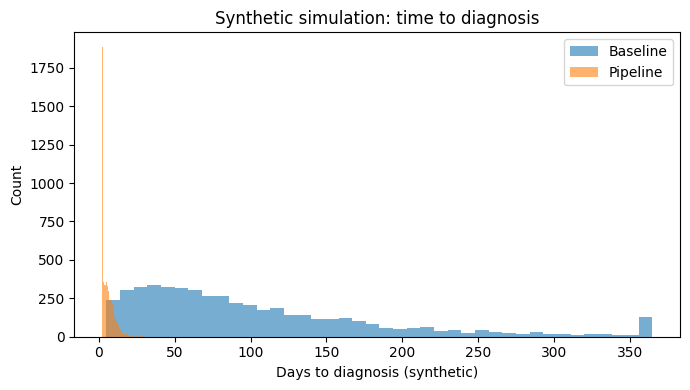

In [ ]:
plt.figure(figsize=(7,4))
plt.hist(df["days_to_dx_baseline"], bins=40, alpha=0.6, label="Baseline")
plt.hist(df["days_to_dx_pipeline"], bins=40, alpha=0.6, label="Pipeline")
plt.xlabel("Days to diagnosis (synthetic)")
plt.ylabel("Count")
plt.legend()
plt.title("Synthetic simulation: time to diagnosis")
plt.tight_layout()
plt.show()


In [ ]:
monitor = pd.DataFrame([
    ["5 years", "Median days to diagnosis", "Decrease", "Pipeline log symptom start to test date"],
    ["5 years", "Missed visit rate", "Decrease", "Scheduled vs attended visits"],
    ["5 years", "Encounters before test", "Decrease", "Encounter count"],
    ["10 years", "Treatment completion rate", "Increase", "Clinic plus CHW registers"],
    ["10 years", "Loss to follow up", "Decrease", "Program retention tracking"],
    ["10 years", "MDR TB completion rate", "Increase", "MDR registry"],
    ["15 years", "TB incidence", "Decrease", "District surveillance"],
    ["15 years", "TB mortality", "Decrease", "Vital registration facility data"]
], columns=["Time_horizon", "Indicator", "Direction", "Data_source"])

monitor


,Time_horizon,Indicator,Direction,Data_source
0,5 years,Median days to diagnosis,Decrease,Pipeline log symptom start to test date
1,5 years,Missed visit rate,Decrease,Scheduled vs attended visits
2,5 years,Encounters before test,Decrease,Encounter count
3,10 years,Treatment completion rate,Increase,Clinic plus CHW registers
4,10 years,Loss to follow up,Decrease,Program retention tracking
5,10 years,MDR TB completion rate,Increase,MDR registry
6,15 years,TB incidence,Decrease,District surveillance
7,15 years,TB mortality,Decrease,Vital registration facility data
